# Understanding and Implementing Gradient Descent

Basics of Neural Networks and Deep Learning.

1. Plain gradient descent on a quadratic error surface with different learning rates
2. Learning rate vs. reaching the global minimum on a non-convex surface
3. A small neural network trained with no normalization, batch norm, and layer norm

Only NumPy and Matplotlib are used, so every gradient is written out by hand. No external dataset is needed because all data is generated in the notebook.

In [1]:
%matplotlib inline
import os
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 12, "axes.titlesize": 13, "legend.fontsize": 11})

out_dir = "figures"
os.makedirs(out_dir, exist_ok=True)
results_log = []


def log(line=""):
    print(line)
    results_log.append(line)

## Part 1: Quadratic error surface

$f(w) = \tfrac12 w^T A w$ with eigenvalues 1 and 10 (condition number 10). Gradient descent is stable only when $\eta < 2/\lambda_{max} = 0.2$.

In [2]:
# A has eigenvalues 1 and 10, so the bowl is stretched (condition number 10).
# Theory says GD is stable only when lr < 2 / largest eigenvalue = 0.2
A = np.array([[1.0, 0.0], [0.0, 10.0]])


def quad_loss(w):
    return 0.5 * w @ A @ w


def quad_grad(w):
    return A @ w


def run_gd(grad_fn, loss_fn, start, lr, steps):
    w = np.array(start, dtype=float)
    path = [w.copy()]
    losses = [loss_fn(w)]
    for _ in range(steps):
        w = w - lr * grad_fn(w)
        path.append(w.copy())
        losses.append(loss_fn(w))
        if not np.isfinite(losses[-1]) or losses[-1] > 1e8:
            break
    return np.array(path), np.array(losses)


start_point = [-9.0, 2.5]
quad_lrs = [0.01, 0.05, 0.10, 0.18, 0.205]
quad_runs = {}
log("PART 1: quadratic f(w) = 0.5*(w1^2 + 10*w2^2), start = (-9, 2.5)")
log(f"{'lr':>7} | {'steps to loss<1e-6':>19} | {'final loss (200 steps)':>22}")
for lr in quad_lrs:
    path, losses = run_gd(quad_grad, quad_loss, start_point, lr, 200)
    quad_runs[lr] = (path, losses)
    hit = np.where(losses < 1e-6)[0]
    steps_needed = str(hit[0]) if len(hit) else "never"
    log(f"{lr:>7} | {steps_needed:>19} | {losses[-1]:>22.3e}")

PART 1: quadratic f(w) = 0.5*(w1^2 + 10*w2^2), start = (-9, 2.5)
     lr |  steps to loss<1e-6 | final loss (200 steps)
   0.01 |               never |              7.270e-01
   0.05 |                 171 |              4.976e-08
    0.1 |                  84 |              2.016e-17
   0.18 |                  45 |              1.358e-33
  0.205 |               never |              1.050e+08


## Part 2: Non-convex surface

$f(x,y) = x^4 - 3x^2 + x + y^2$ has a global minimum near $x=-1.30$ and a local minimum near $x=1.13$. 500 random starts are run for each learning rate.

In [3]:
# f(x, y) = x^4 - 3x^2 + x + y^2
# global min near x = -1.30, local min near x = 1.13 (both at y = 0)


def bumpy_loss(w):
    x, y = w
    return x**4 - 3 * x**2 + x + y**2


def bumpy_grad(w):
    x, y = w
    return np.array([4 * x**3 - 6 * x + 1, 2 * y])


global_x = -1.3008
rng = np.random.default_rng(0)
# starts are spread evenly over the box so every lr sees the same starts
starts = rng.uniform([-2.0, -2.0], [2.0, 2.0], size=(500, 2))
bumpy_lrs = [0.01, 0.05, 0.10, 0.13, 0.15, 0.20]
log()
log("PART 2: non-convex f(x,y) = x^4 - 3x^2 + x + y^2, 500 random starts in [-2,2]^2")
log(f"{'lr':>6} | {'% reached global min':>21} | {'% local min':>11} | {'% diverged/oscillating':>22}")
outcome_rates = {}
for lr in bumpy_lrs:
    got_global = got_local = other = 0
    for s in starts:
        path, losses = run_gd(bumpy_grad, bumpy_loss, s, lr, 2000)
        end = path[-1]
        # "other" = never settled (bouncing between points or blowing up)
        if not np.all(np.isfinite(end)) or np.linalg.norm(bumpy_grad(end)) > 1e-3:
            other += 1
        elif end[0] < 0:
            got_global += 1
        else:
            got_local += 1
    n = len(starts)
    outcome_rates[lr] = (100 * got_global / n, 100 * got_local / n, 100 * other / n)
    log(f"{lr:>6} | {100*got_global/n:>21.1f} | {100*got_local/n:>11.1f} | {100*other/n:>22.1f}")

# one start inside the global basin: the small lr settles, the big one cannot
# because the global min is sharper (curvature ~14.3, so it needs lr < 2/14.3 = 0.14)
demo_start = [-0.4, 1.8]
demo_lrs = [0.05, 0.15]
demo_runs = {lr: run_gd(bumpy_grad, bumpy_loss, demo_start, lr, 300) for lr in demo_lrs}
for lr, (p, _) in demo_runs.items():
    log(f"  demo start (-0.4, 1.8), lr={lr}: last two x values {p[-2][0]:.3f}, {p[-1][0]:.3f}")


PART 2: non-convex f(x,y) = x^4 - 3x^2 + x + y^2, 500 random starts in [-2,2]^2
    lr |  % reached global min | % local min | % diverged/oscillating
  0.01 |                  47.8 |        52.2 |                    0.0
  0.05 |                  47.8 |        52.2 |                    0.0
   0.1 |                  50.8 |        49.2 |                    0.0
  0.13 |                  53.0 |        47.0 |                    0.0
  0.15 |                   0.0 |        45.6 |                   54.4
   0.2 |                   0.0 |        43.6 |                   56.4
  demo start (-0.4, 1.8), lr=0.05: last two x values -1.301, -1.301
  demo start (-0.4, 1.8), lr=0.15: last two x values -1.085, -1.445


### Figure 1: gradient descent on the quadratic surface

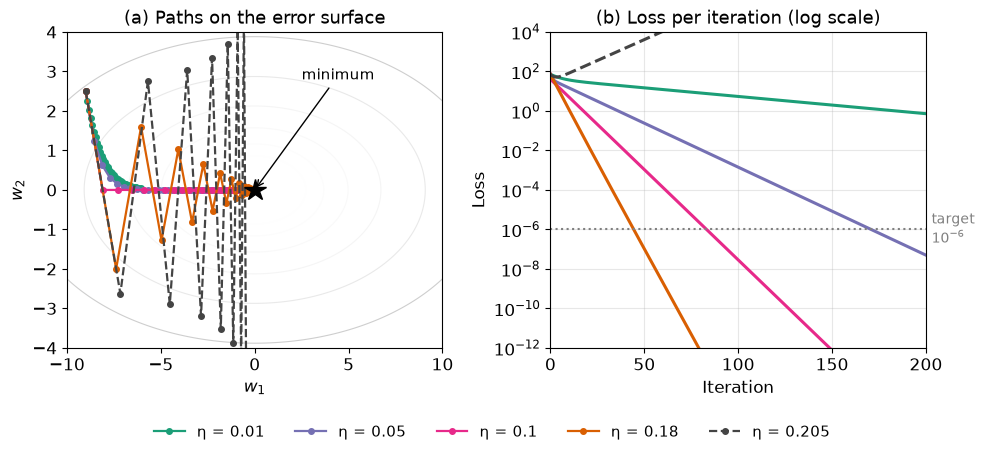

In [4]:
colors = ["#1b9e77", "#7570b3", "#e7298a", "#d95f02", "#444444"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))

gx, gy = np.meshgrid(np.linspace(-10, 10, 300), np.linspace(-4, 4, 300))
gz = 0.5 * (gx**2 + 10 * gy**2)
axes[0].contour(gx, gy, gz, levels=np.logspace(-1, 2.4, 14), cmap="Greys", linewidths=0.8)
for lr, c in zip(quad_lrs, colors):
    # the diverging run is cut short so it doesn't hide the others
    p = quad_runs[lr][0][:40 if lr < 0.2 else 14]
    p = p[np.all(np.abs(p) < 12, axis=1)]
    style = "--o" if lr > 0.2 else "-o"
    axes[0].plot(p[:, 0], p[:, 1], style, ms=4, lw=1.6, color=c, label=f"η = {lr}")
axes[0].plot(0, 0, "k*", ms=16, zorder=5)
axes[0].annotate("minimum", (0, 0), (2.5, 2.8), fontsize=11, arrowprops=dict(arrowstyle="->"))
axes[0].set_xlim(-10, 10)
axes[0].set_ylim(-4, 4)
axes[0].set_title("(a) Paths on the error surface")
axes[0].set_xlabel("$w_1$")
axes[0].set_ylabel("$w_2$")

for lr, c in zip(quad_lrs, colors):
    style = "--" if lr > 0.2 else "-"
    axes[1].semilogy(quad_runs[lr][1], style, color=c, lw=2.2)
axes[1].axhline(1e-6, ls=":", color="grey", lw=1.5)
axes[1].text(203, 1e-6, "target\n$10^{-6}$", va="center", fontsize=10, color="grey")
axes[1].set_ylim(1e-12, 1e4)
axes[1].set_xlim(0, 200)
axes[1].set_title("(b) Loss per iteration (log scale)")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Loss")
axes[1].grid(alpha=0.3)

fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=5, frameon=False)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.savefig(f"{out_dir}/fig1_quadratic.png", dpi=300)
plt.show()

### Figure 2: the non-convex surface

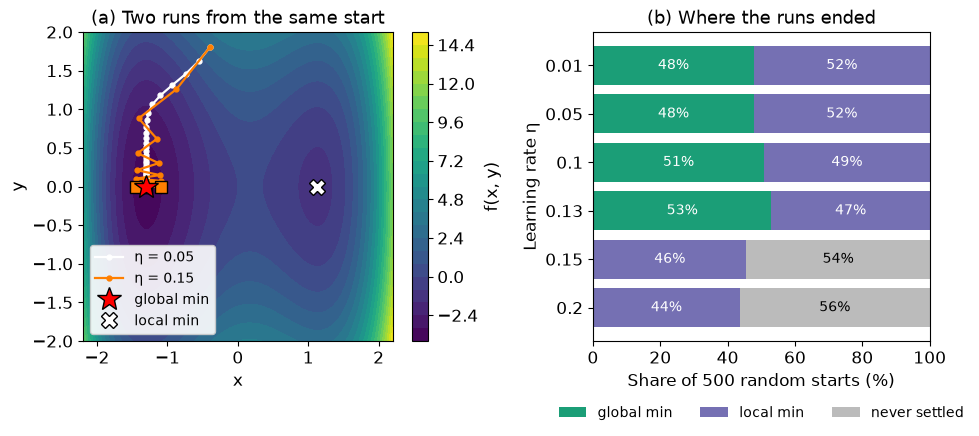

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})

bx, by = np.meshgrid(np.linspace(-2.2, 2.2, 300), np.linspace(-2, 2, 300))
bz = bx**4 - 3 * bx**2 + bx + by**2
cf = axes[0].contourf(bx, by, bz, levels=30, cmap="viridis")
fig.colorbar(cf, ax=axes[0], label="f(x, y)")
for lr, c in zip(demo_lrs, ["white", "#ff7f00"]):
    p = demo_runs[lr][0]
    axes[0].plot(p[:, 0], p[:, 1], "-o", ms=3.5, lw=1.6, color=c, label=f"η = {lr}")
    axes[0].plot(p[-2:, 0], p[-2:, 1], "s", ms=8, color=c, mec="k")
axes[0].plot(global_x, 0, "r*", ms=18, mec="k", label="global min")
axes[0].plot(1.1309, 0, "X", color="white", ms=12, mec="k", label="local min")
axes[0].set_title("(a) Two runs from the same start")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].legend(fontsize=10, loc="lower left", framealpha=0.9)

lr_labels = [str(lr) for lr in bumpy_lrs]
g = np.array([outcome_rates[lr][0] for lr in bumpy_lrs])
l = np.array([outcome_rates[lr][1] for lr in bumpy_lrs])
o = np.array([outcome_rates[lr][2] for lr in bumpy_lrs])
ypos = np.arange(len(bumpy_lrs))
axes[1].barh(ypos, g, color="#1b9e77", label="global min")
axes[1].barh(ypos, l, left=g, color="#7570b3", label="local min")
axes[1].barh(ypos, o, left=g + l, color="#bbbbbb", label="never settled")
for yi, (a, b, cnt) in enumerate(zip(g, l, o)):
    for start, width in ((0, a), (a, b), (a + b, cnt)):
        if width >= 8:
            axes[1].text(start + width / 2, yi, f"{width:.0f}%", ha="center", va="center",
                         fontsize=10, color="white" if width is not cnt else "black")
axes[1].set_yticks(ypos, lr_labels)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 100)
axes[1].set_xlabel("Share of 500 random starts (%)")
axes[1].set_ylabel("Learning rate η")
axes[1].set_title("(b) Where the runs ended")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False, fontsize=10)

plt.tight_layout()
plt.savefig(f"{out_dir}/fig2_nonconvex.png", dpi=300)
plt.show()

## Part 3: Normalization in a small network

Three-class spiral data, five hidden layers of 64 ReLU units, mini-batch gradient descent. The forward and backward passes for batch norm and layer norm are written by hand and checked numerically.

In [6]:
def make_spiral(n_per_class=300, n_classes=3, noise=0.25, seed=0):
    r = np.random.default_rng(seed)
    X, y = [], []
    for k in range(n_classes):
        t = np.linspace(0.0, 1.0, n_per_class)
        angle = t * 4.0 + k * 2 * np.pi / n_classes + r.normal(0, noise, n_per_class)
        X.append(np.c_[t * np.sin(angle), t * np.cos(angle)])
        y.append(np.full(n_per_class, k))
    return np.vstack(X), np.concatenate(y)


class TinyNet:
    """MLP: input -> [Linear -> (norm) -> ReLU] x n_hidden -> Linear -> softmax"""

    def __init__(self, sizes, norm="none", seed=0, init_std=0.1):
        r = np.random.default_rng(seed)
        self.norm = norm
        self.W, self.b, self.gamma, self.beta = [], [], [], []
        self.run_mean, self.run_var = [], []
        for i in range(len(sizes) - 1):
            # a plain small init (std 0.1) on purpose instead of He init, so the deep
            # unnormalized net starts with a shrinking signal, which is the case
            # where normalization is supposed to help
            self.W.append(r.normal(0, init_std, (sizes[i], sizes[i + 1])))
            self.b.append(np.zeros(sizes[i + 1]))
            self.gamma.append(np.ones(sizes[i + 1]))
            self.beta.append(np.zeros(sizes[i + 1]))
            self.run_mean.append(np.zeros(sizes[i + 1]))
            self.run_var.append(np.ones(sizes[i + 1]))
        self.n_layers = len(self.W)
        self.eps = 1e-5

    def _norm_forward(self, z, i, train):
        if self.norm == "batch":
            if train:
                mu, var = z.mean(0), z.var(0)
                self.run_mean[i] = 0.9 * self.run_mean[i] + 0.1 * mu
                self.run_var[i] = 0.9 * self.run_var[i] + 0.1 * var
            else:
                mu, var = self.run_mean[i], self.run_var[i]
        else:  # layer norm: stats over the features of each sample
            mu = z.mean(1, keepdims=True)
            var = z.var(1, keepdims=True)
        inv_std = 1.0 / np.sqrt(var + self.eps)
        z_hat = (z - mu) * inv_std
        return self.gamma[i] * z_hat + self.beta[i], (z_hat, inv_std)

    def _norm_backward(self, d_out, i, cache):
        z_hat, inv_std = cache
        d_gamma = (d_out * z_hat).sum(0)
        d_beta = d_out.sum(0)
        d_zhat = d_out * self.gamma[i]
        axis = 0 if self.norm == "batch" else 1
        n = d_zhat.shape[axis]
        d_z = (inv_std / n) * (
            n * d_zhat
            - d_zhat.sum(axis, keepdims=True)
            - z_hat * (d_zhat * z_hat).sum(axis, keepdims=True)
        )
        return d_z, d_gamma, d_beta

    def forward(self, X, train=True):
        caches = []
        h = X
        for i in range(self.n_layers):
            z = h @ self.W[i] + self.b[i]
            if i == self.n_layers - 1:
                caches.append((h, None, None))
                return z, caches
            norm_cache = None
            if self.norm != "none":
                z, norm_cache = self._norm_forward(z, i, train)
            a = np.maximum(z, 0)
            caches.append((h, norm_cache, z))
            h = a

    def loss_and_grads(self, X, y):
        logits, caches = self.forward(X, train=True)
        logits = logits - logits.max(1, keepdims=True)
        probs = np.exp(logits)
        probs /= probs.sum(1, keepdims=True)
        n = len(y)
        loss = -np.log(probs[np.arange(n), y] + 1e-12).mean()

        d = probs
        d[np.arange(n), y] -= 1
        d /= n
        grads = {"W": [None] * self.n_layers, "b": [None] * self.n_layers,
                 "gamma": [None] * self.n_layers, "beta": [None] * self.n_layers}
        for i in reversed(range(self.n_layers)):
            h_in, norm_cache, z_after_norm = caches[i]
            if i != self.n_layers - 1:
                d = d * (z_after_norm > 0)
                if self.norm != "none":
                    d, grads["gamma"][i], grads["beta"][i] = self._norm_backward(d, i, norm_cache)
            grads["W"][i] = h_in.T @ d
            grads["b"][i] = d.sum(0)
            d = d @ self.W[i].T
        return loss, grads

    def step(self, grads, lr):
        for i in range(self.n_layers):
            self.W[i] -= lr * grads["W"][i]
            self.b[i] -= lr * grads["b"][i]
            if grads["gamma"][i] is not None:
                self.gamma[i] -= lr * grads["gamma"][i]
                self.beta[i] -= lr * grads["beta"][i]

    def evaluate(self, X, y):
        logits, _ = self.forward(X, train=False)
        logits = logits - logits.max(1, keepdims=True)
        probs = np.exp(logits)
        probs /= probs.sum(1, keepdims=True)
        loss = -np.log(probs[np.arange(len(y)), y] + 1e-12).mean()
        acc = (probs.argmax(1) == y).mean()
        return loss, acc


def gradient_check():
    # quick numerical check that the hand-written backward passes are right
    r = np.random.default_rng(1)
    Xc = r.normal(size=(8, 2))
    yc = r.integers(0, 3, 8)
    worst = 0.0
    for norm in ["none", "batch", "layer"]:
        net = TinyNet([2, 5, 5, 3], norm=norm, seed=3)
        _, g = net.loss_and_grads(Xc, yc)
        for i, j in [(0, (0, 1)), (1, (2, 3)), (2, (4, 0))]:
            old = net.W[i][j]
            net.W[i][j] = old + 1e-5
            lp, _ = net.loss_and_grads(Xc, yc)
            net.W[i][j] = old - 1e-5
            lm, _ = net.loss_and_grads(Xc, yc)
            net.W[i][j] = old
            num = (lp - lm) / 2e-5
            rel = abs(num - g["W"][i][j]) / max(1e-8, abs(num) + abs(g["W"][i][j]))
            worst = max(worst, rel)
    return worst


log()
log(f"PART 3: gradient check, worst relative error = {gradient_check():.2e}")


PART 3: gradient check, worst relative error = 4.45e-08


### Training: no normalization vs. batch norm vs. layer norm (3 seeds each, takes about 30 s)

In [7]:
X_all, y_all = make_spiral()
perm = np.random.default_rng(42).permutation(len(y_all))
X_all, y_all = X_all[perm], y_all[perm]
split = int(0.8 * len(y_all))
X_train, y_train = X_all[:split], y_all[:split]
X_test, y_test = X_all[split:], y_all[split:]

layer_sizes = [2, 64, 64, 64, 64, 64, 3]
norm_types = ["none", "batch", "layer"]
nice_name = {"none": "No normalization", "batch": "Batch norm", "layer": "Layer norm"}
nn_lrs = [0.05, 0.2]
epochs = 150
batch_size = 64
seeds = [0, 1, 2]

curves = {}
log(f"Spiral data, 3 classes, {len(y_train)} train / {len(y_test)} test, net {layer_sizes}")
log(f"mini-batch GD, batch {batch_size}, {epochs} epochs, mean of {len(seeds)} seeds")
log(f"{'lr':>5} | {'method':>17} | {'last-10 avg loss':>16} | {'test acc %':>10} | {'epochs to loss<0.3':>18}")
for lr in nn_lrs:
    for norm in norm_types:
        all_losses, all_accs = [], []
        for seed in seeds:
            net = TinyNet(layer_sizes, norm=norm, seed=seed)
            shuffle_rng = np.random.default_rng(100 + seed)
            epoch_losses = []
            for ep in range(epochs):
                order = shuffle_rng.permutation(len(y_train))
                for k in range(0, len(order), batch_size):
                    idx = order[k:k + batch_size]
                    _, g = net.loss_and_grads(X_train[idx], y_train[idx])
                    net.step(g, lr)
                tr_loss, _ = net.evaluate(X_train, y_train)
                epoch_losses.append(tr_loss if np.isfinite(tr_loss) else np.nan)
            all_losses.append(epoch_losses)
            all_accs.append(net.evaluate(X_test, y_test)[1])
        mean_curve = np.nanmean(np.array(all_losses), axis=0)
        # mini-batch noise makes single epochs jumpy, so trends are read off a
        # 5-epoch moving average and "final loss" is the mean of the last 10 epochs
        smooth_curve = np.convolve(mean_curve, np.ones(5) / 5, mode="valid")
        curves[(lr, norm)] = (mean_curve, smooth_curve)
        below = np.where(smooth_curve < 0.3)[0]
        ep_needed = str(below[0] + 5) if len(below) else f">{epochs}"
        log(f"{lr:>5} | {nice_name[norm]:>17} | {mean_curve[-10:].mean():>16.3f} | {100*np.mean(all_accs):>10.1f} | {ep_needed:>18}")

Spiral data, 3 classes, 720 train / 180 test, net [2, 64, 64, 64, 64, 64, 3]
mini-batch GD, batch 64, 150 epochs, mean of 3 seeds
   lr |            method | last-10 avg loss | test acc % | epochs to loss<0.3
 0.05 |  No normalization |            0.119 |       98.1 |                 74
 0.05 |        Batch norm |            0.065 |       96.5 |                  9
 0.05 |        Layer norm |            0.061 |       98.3 |                 17
  0.2 |  No normalization |            0.067 |       98.3 |                 41
  0.2 |        Batch norm |            0.101 |       93.7 |                 11
  0.2 |        Layer norm |            0.140 |       94.3 |                 41


### Figure 3: training loss curves

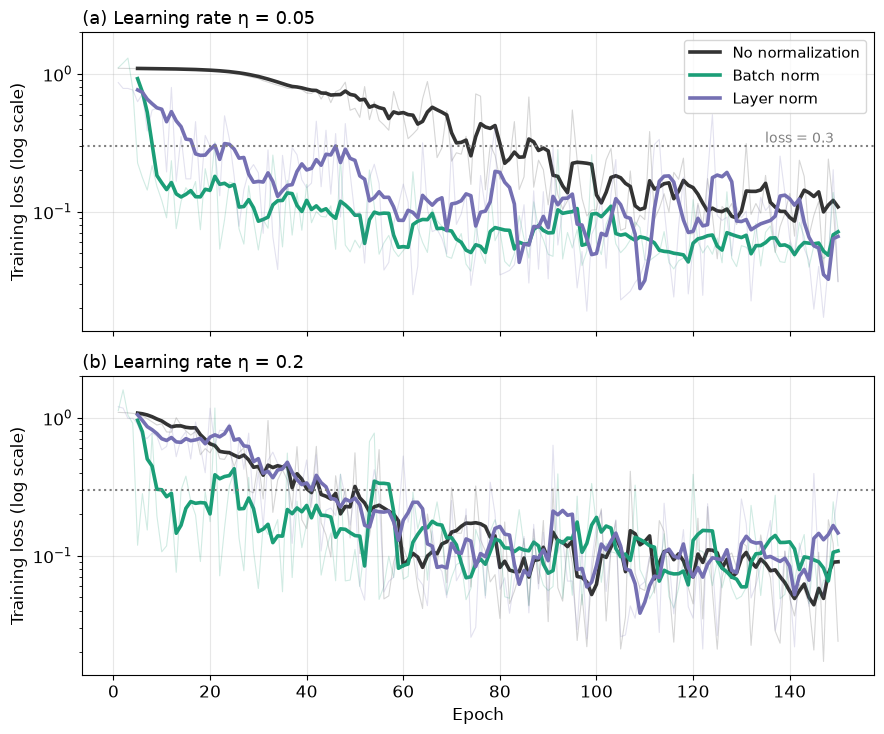

In [8]:
norm_colors = {"none": "#333333", "batch": "#1b9e77", "layer": "#7570b3"}
fig, axes = plt.subplots(2, 1, figsize=(9, 7.5), sharex=True, sharey=True)
for ax, lr, tag in zip(axes, nn_lrs, ["(a)", "(b)"]):
    for norm in norm_types:
        raw, smooth = curves[(lr, norm)]
        ax.plot(np.arange(1, epochs + 1), raw, color=norm_colors[norm], lw=0.8, alpha=0.2)
        ax.plot(np.arange(5, epochs + 1), smooth, color=norm_colors[norm], lw=2.6,
                label=nice_name[norm])
    ax.axhline(0.3, ls=":", color="grey", lw=1.5)
    ax.set_title(f"{tag} Learning rate η = {lr}", loc="left")
    ax.set_yscale("log")
    ax.set_ylabel("Training loss (log scale)")
    ax.grid(alpha=0.3)
axes[1].set_xlabel("Epoch")
axes[0].legend(loc="upper right", fontsize=11)
axes[0].text(150, 0.3, "loss = 0.3 ", ha="right", va="bottom", fontsize=10, color="grey")
plt.tight_layout()
plt.savefig(f"{out_dir}/fig3_normalization.png", dpi=300)
plt.show()

In [9]:
with open(f"{out_dir}/results.txt", "w") as f:
    f.write("\n".join(results_log) + "\n")
print(f"\nSaved figures and results to ./{out_dir}")


Saved figures and results to ./figures
